In [9]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [10]:
# Read and process BYD & Tesla data
byd_tesla_path = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\Data\BYD&Tesla.xlsx'
byd_tesla = pd.read_excel(
    byd_tesla_path,
    header=0,
    skiprows=[0],
    index_col='日期',
    parse_dates=['日期'],
)
byd_tesla = byd_tesla[['比亚迪股份', '特斯拉(TESLA)']].dropna()
byd_monthly = byd_tesla['比亚迪股份'].resample('M').last().pct_change().dropna().to_frame(name='BYD')
tesla_monthly = byd_tesla['特斯拉(TESLA)'].resample('M').last().pct_change().dropna().to_frame(name='Tesla')

# Read and process HSI & Nasdaq data
hsi_nasdaq_path = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\Data\恒生&纳斯达克.xlsx'
hsi_nasdaq = pd.read_excel(
    hsi_nasdaq_path,
    header=0,
    skiprows=[0],
    index_col='日期',
    parse_dates=['日期'],
)
hsi_nasdaq = hsi_nasdaq[['恒生指数', '纳斯达克指数']].dropna()
hsi_monthly = hsi_nasdaq['恒生指数'].resample('M').last().pct_change().dropna().to_frame(name='HSI')
nasdaq_monthly = hsi_nasdaq['纳斯达克指数'].resample('M').last().pct_change().dropna().to_frame(name='Nasdaq')

# Read and process HongKong factors
hongkong_path = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\Data\HongKong.xlsx'
hongkong = pd.read_excel(hongkong_path)
hongkong['Date'] = pd.to_datetime(hongkong['YearMonth'], format='%Y%m') + pd.offsets.MonthEnd(1)
hongkong.set_index('Date', inplace=True)
for col in ['Mkt', 'BE/ME High', 'BE/ME Low', 'E/P High', 'E/P Low', 'CE/P High', 'CE/P Low', 'Yld High', 'Yld Low']:
    hongkong[col] /= 100  # Convert percentages to decimals
hongkong['BE/ME_factor'] = hongkong['BE/ME High'] - hongkong['BE/ME Low']
hongkong['E/P_factor'] = hongkong['E/P High'] - hongkong['E/P Low']
hongkong['CE/P_factor'] = hongkong['CE/P High'] - hongkong['CE/P Low']
hongkong['Yld_factor'] = hongkong['Yld High'] - hongkong['Yld Low']
hongkong_factors = hongkong[['Mkt', 'BE/ME_factor', 'E/P_factor', 'CE/P_factor', 'Yld_factor']]

# Read and process Nasdaq factors
nasdaq_factors_path = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\Data\Nasdaq.xlsx'
nasdaq_factors = pd.read_excel(nasdaq_factors_path)
nasdaq_factors['Date'] = pd.to_datetime(nasdaq_factors['YearMonth'], format='%Y%m') + pd.offsets.MonthEnd(1)
nasdaq_factors.set_index('Date', inplace=True)
for col in ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']:
    nasdaq_factors[col] /= 100  # Convert percentages to decimals

# Merge data for analysis
merged_byd = pd.merge(byd_monthly, hongkong_factors, left_index=True, right_index=True)
merged_tesla = pd.merge(tesla_monthly, nasdaq_factors, left_index=True, right_index=True)
merged_tesla['Tesla_excess'] = merged_tesla['Tesla'] - merged_tesla['RF']

In [11]:
def create_results_table(model, title, dep_var, factors, factor_labels):
    """Create styled table for regression results with multiple factors"""
    plt.figure(figsize=(4, 6))
    ax = plt.gca()
    ax.axis('off')
    
    # Extract metrics
    alpha = model.params['const']
    alpha_p = model.pvalues['const']
    r_squared = model.rsquared
    obs = model.nobs
    
    # Prepare cell content
    cell_text = []
    cell_colors = []
    
    # Model Information
    cell_text.append(['Model Information', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    cell_text.append(['  Dependent Variable', dep_var])
    cell_colors.append(['#ffffff', '#ffffff'])
    cell_text.append(['  Number of Observations', f"{obs:,}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Coefficients Section
    cell_text.append(['Coefficients', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    
    # Intercept
    cell_text.append(['  Intercept (α)', f"{alpha:.4f}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    alpha_p_str = f"{alpha_p:.4f}" if alpha_p >= 0.0001 else f"{alpha_p:.2e}"
    cell_text.append(['  p-value', alpha_p_str])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Factors
    for factor, label in zip(factors, factor_labels):
        beta = model.params[factor]
        beta_p = model.pvalues[factor]
        cell_text.append([f'  {label} (β)', f"{beta:.4f}"])
        cell_colors.append(['#ffffff', '#ffffff'])
        beta_p_str = f"{beta_p:.4f}" if beta_p >= 0.0001 else f"{beta_p:.2e}"
        cell_text.append(['  p-value', beta_p_str])
        cell_colors.append(['#ffffff', '#ffffff'])
    
    # Model Fit
    cell_text.append(['Model Fit', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    cell_text.append(['  R-squared', f"{r_squared:.4f}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Create table
    table = ax.table(
        cellText=cell_text,
        cellColours=cell_colors,
        colLabels=['Metric', 'Value'],
        loc='center',
        cellLoc='left'
    )
    
    # Formatting
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1.2, 1.5)
    
    # Style headers and sections
    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#40466e')
        else:
            adjusted_row = row - 1
            if adjusted_row < len(cell_text):
                metric_name = cell_text[adjusted_row][0].strip()
                if metric_name in ['Model Information', 'Coefficients', 'Model Fit']:
                    cell.set_text_props(weight='bold')

    plt.title(title, fontsize=14, pad=20)
    plt.tight_layout()
    return plt.gcf()

def create_simple_results_table(model, title, dep_var, indep_var):
    """Create styled table for simple regression results"""
    plt.figure(figsize=(5, 5))
    ax = plt.gca()
    ax.axis('off')
    
    # Extract metrics
    alpha = model.params['const']
    alpha_p = model.pvalues['const']
    beta = model.params[indep_var]
    beta_p = model.pvalues[indep_var]
    r_squared = model.rsquared
    obs = model.nobs
    
    # Prepare cell content
    cell_text = []
    cell_colors = []
    
    # Model Information
    cell_text.append(['Model Information', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    cell_text.append(['  Dependent Variable', dep_var])
    cell_colors.append(['#ffffff', '#ffffff'])
    cell_text.append(['  Independent Variable', indep_var])
    cell_colors.append(['#ffffff', '#ffffff'])
    cell_text.append(['  Number of Observations', f"{obs:,}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Coefficients Section
    cell_text.append(['Coefficients', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    
    # Intercept
    cell_text.append(['  Intercept (α)', f"{alpha:.4f}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    alpha_p_str = f"{alpha_p:.4f}" if alpha_p >= 0.0001 else f"{alpha_p:.2e}"
    cell_text.append(['  p-value', alpha_p_str])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Beta
    cell_text.append(['  Beta (β)', f"{beta:.4f}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    beta_p_str = f"{beta_p:.4f}" if beta_p >= 0.0001 else f"{beta_p:.2e}"
    cell_text.append(['  p-value', beta_p_str])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Model Fit
    cell_text.append(['Model Fit', ''])
    cell_colors.append(['#d3d3d3', '#d3d3d3'])
    cell_text.append(['  R-squared', f"{r_squared:.4f}"])
    cell_colors.append(['#ffffff', '#ffffff'])
    
    # Create table
    table = ax.table(
        cellText=cell_text,
        cellColours=cell_colors,
        colLabels=['Metric', 'Value'],
        loc='center',
        cellLoc='left'
    )
    
    # Formatting
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1.2, 1.5)
    
    # Style headers and sections
    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#40466e')
        else:
            adjusted_row = row - 1
            if adjusted_row < len(cell_text):
                metric_name = cell_text[adjusted_row][0].strip()
                if metric_name in ['Model Information', 'Coefficients', 'Model Fit']:
                    cell.set_text_props(weight='bold')

    plt.title(title, fontsize=14, pad=20)
    plt.tight_layout()
    return plt.gcf()

# 1. APT Model Analysis

### 1.1 BYD APT Model

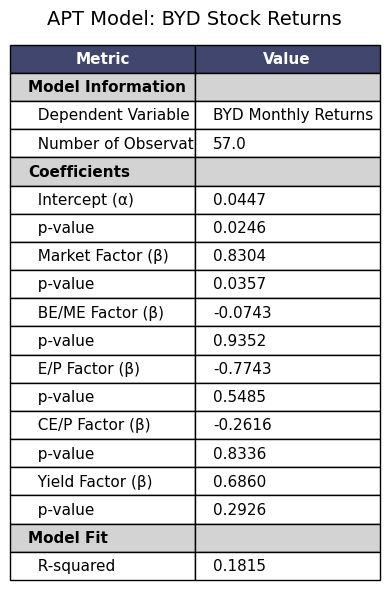

In [12]:
# Run regression
X_byd = sm.add_constant(merged_byd[['Mkt', 'BE/ME_factor', 'E/P_factor', 'CE/P_factor', 'Yld_factor']])
model_byd = sm.OLS(merged_byd['BYD'], X_byd).fit()

# Generate table
fig_byd = create_results_table(
    model_byd,
    "APT Model: BYD Stock Returns",
    "BYD Monthly Returns",
    ['Mkt', 'BE/ME_factor', 'E/P_factor', 'CE/P_factor', 'Yld_factor'],
    ['Market Factor', 'BE/ME Factor', 'E/P Factor', 'CE/P Factor', 'Yield Factor']
)
plt.show()

### 1.2 Tesla APT Model

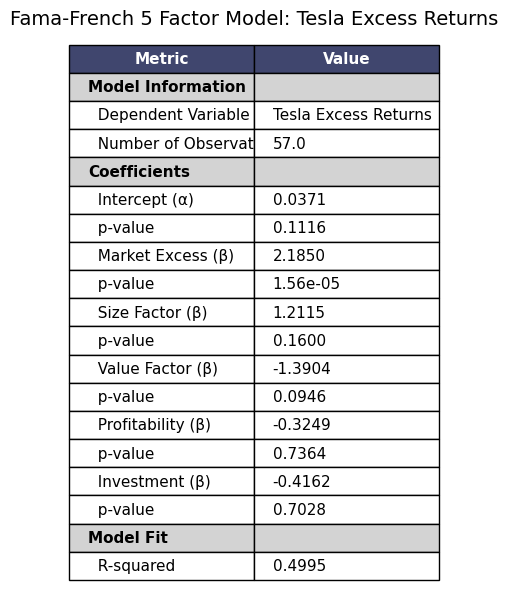

In [13]:
# Run regression
X_tesla = sm.add_constant(merged_tesla[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']])
model_tesla = sm.OLS(merged_tesla['Tesla_excess'], X_tesla).fit()

# Generate table
fig_tesla = create_results_table(
    model_tesla,
    "Fama-French 5 Factor Model: Tesla Excess Returns",
    "Tesla Excess Returns",
    ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA'],
    ['Market Excess', 'Size Factor', 'Value Factor', 'Profitability', 'Investment']
)
plt.show()

# 2. Market Beta Analysis

### 2.1 BYD Beta to HSI

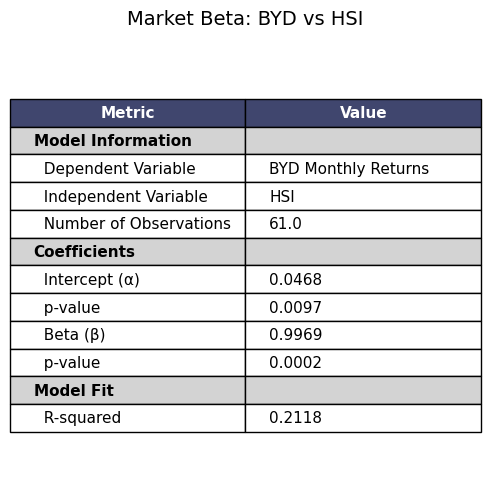

In [14]:
merged_byd_hsi = pd.merge(byd_monthly, hsi_monthly, left_index=True, right_index=True)
model_byd_hsi = sm.OLS(merged_byd_hsi['BYD'], sm.add_constant(merged_byd_hsi['HSI'])).fit()
fig_beta_byd = create_simple_results_table(
    model_byd_hsi,
    "Market Beta: BYD vs HSI",
    "BYD Monthly Returns",
    "HSI"
)
plt.show()

### 2.2 Tesla Beta to Nasdaq

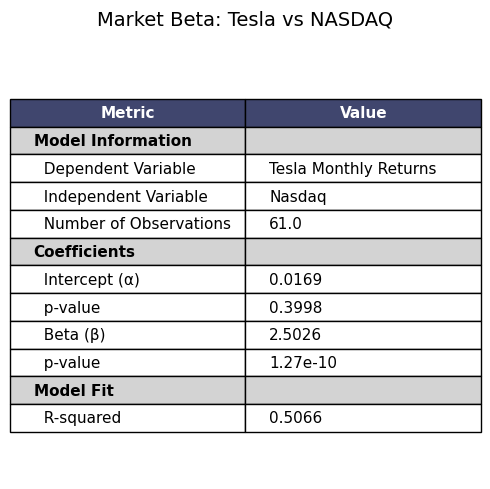

In [15]:
merged_tesla_nasdaq = pd.merge(tesla_monthly, nasdaq_monthly, left_index=True, right_index=True)
model_tesla_nasdaq = sm.OLS(merged_tesla_nasdaq['Tesla'], sm.add_constant(merged_tesla_nasdaq['Nasdaq'])).fit()
fig_beta_tesla = create_simple_results_table(
    model_tesla_nasdaq,
    "Market Beta: Tesla vs NASDAQ",
    "Tesla Monthly Returns",
    "Nasdaq"
)
plt.show()

### 2.3 Spread Analysis

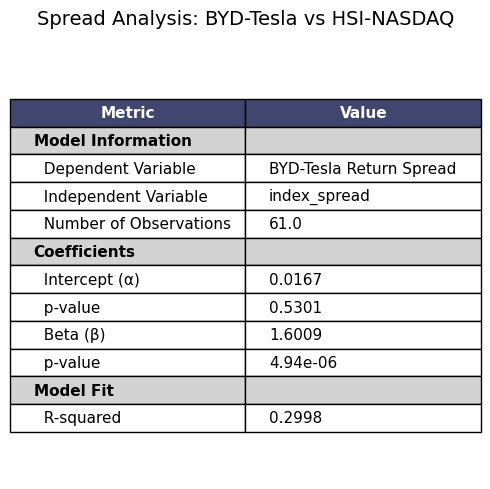

In [16]:
merged_spread = pd.merge(merged_byd_hsi, merged_tesla_nasdaq, left_index=True, right_index=True)
merged_spread['stock_spread'] = merged_spread['BYD'] - merged_spread['Tesla']
merged_spread['index_spread'] = merged_spread['HSI'] - merged_spread['Nasdaq']
model_spread = sm.OLS(merged_spread['stock_spread'], sm.add_constant(merged_spread['index_spread'])).fit()

fig_spread = create_simple_results_table(
    model_spread,
    "Spread Analysis: BYD-Tesla vs HSI-NASDAQ",
    "BYD-Tesla Return Spread",
    "index_spread"
)
plt.show()